<a href="https://colab.research.google.com/github/erickcorrea3092/Python-basics-course/blob/main/11_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cargando bibliotecas
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
# Cargando el dataset
california = fetch_california_housing()
# Mostrando la descripcion del dataset
print(california.DESCR)
print(california.keys())
print(california)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [ ]:
print(california.data.shape)
print(california.target.shape)

(20640, 8)
(20640,)


In [ ]:
# Explorando los datos
pd.set_option('display.precision', 3) # Changed 'precision' to 'display.precision'
pd.set_option('display.width', None)

california_df = pd.DataFrame(california.data,
                              columns=california.feature_names)
california_df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24


In [ ]:
california_df['MedHouseValue'] = pd.Series(california.target)
california_df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521


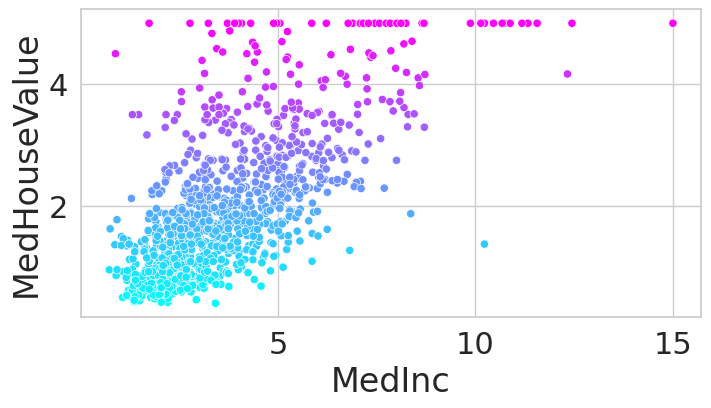

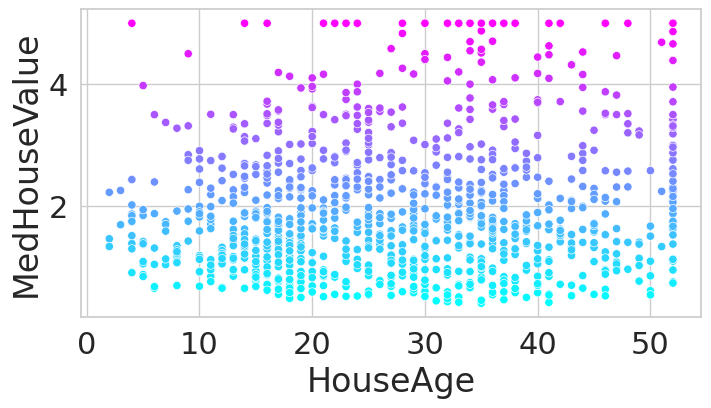

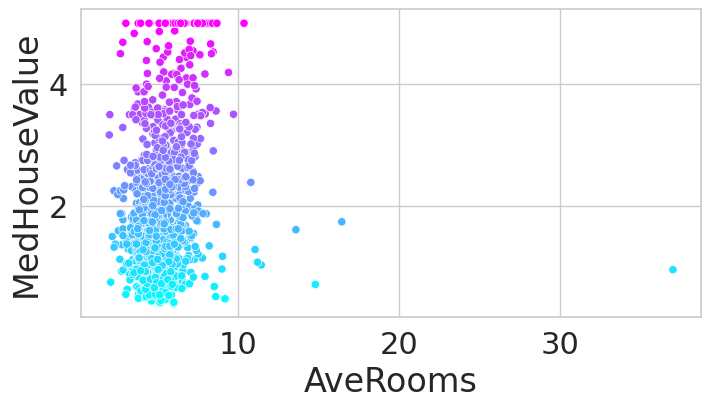

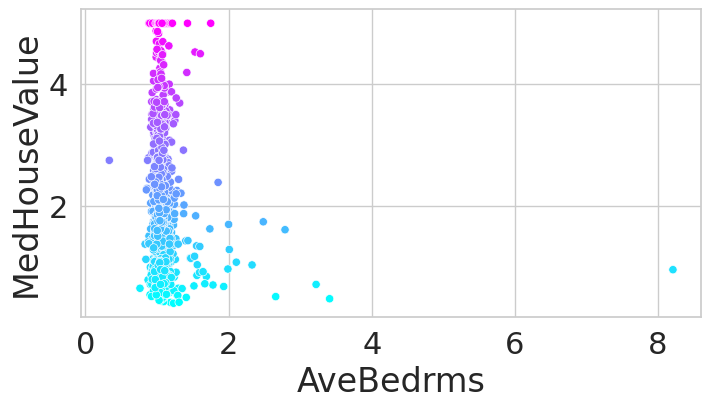

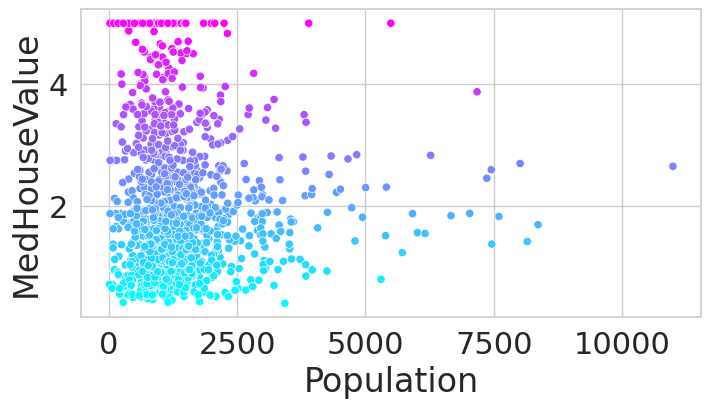

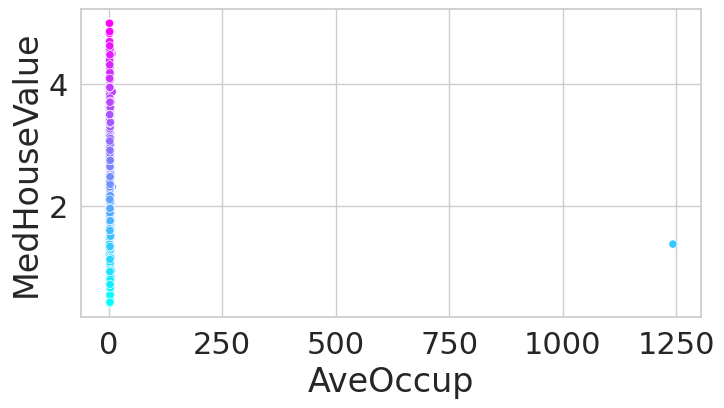

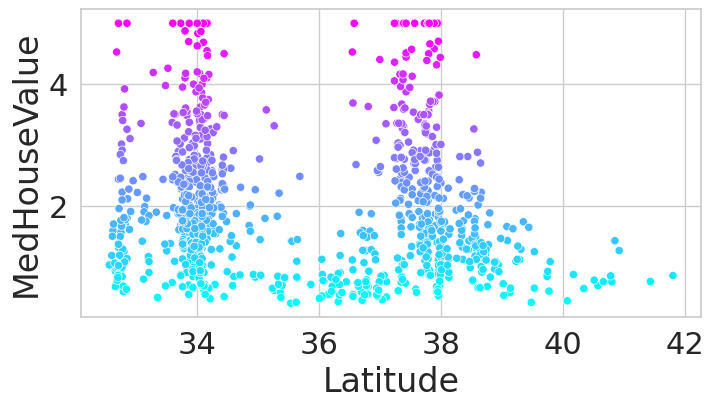

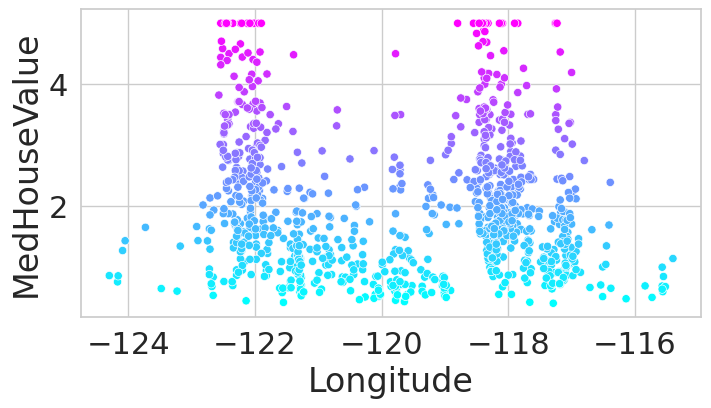

In [ ]:
# Observando las caracteristicas de los datos
sample_df = california_df.sample(frac=0.05)

sns.set(font_scale=2)
sns.set_style('whitegrid')

for feature in california.feature_names:
     plt.figure(figsize=(8, 4))
     sns.scatterplot(data=sample_df, x=feature,
                     y='MedHouseValue', hue='MedHouseValue',
                     palette='cool', legend=False)

In [ ]:
# Separando los datos para entrenamiento y prueba
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
     california.data, california.target)

# Se muestra la forma de los datosk
print(X_train.shape)
print(X_test.shape)

(15480, 8)
(5160, 8)


In [ ]:
# Entrenando el modelo
from sklearn.linear_model import LinearRegression

linear_regression = LinearRegression()
linear_regression.fit(X=X_train, y=y_train)

LinearRegression()

In [ ]:
# Probando el modelo
predicted = linear_regression.predict(X_test)
expected = y_test
print(predicted[:15])
print(expected[:15])

[1.25940728 1.9658653  1.91352944 3.39527065 1.63328193 2.87292761
 2.94000112 0.9479579  1.81905067 1.90945771 1.84747166 2.13437051
 3.03639305 2.08709588 2.25817844]
[0.833   5.00001 2.015   5.00001 0.98    2.233   3.975   0.608   1.425
 1.714   1.557   1.538   5.00001 2.102   2.221  ]


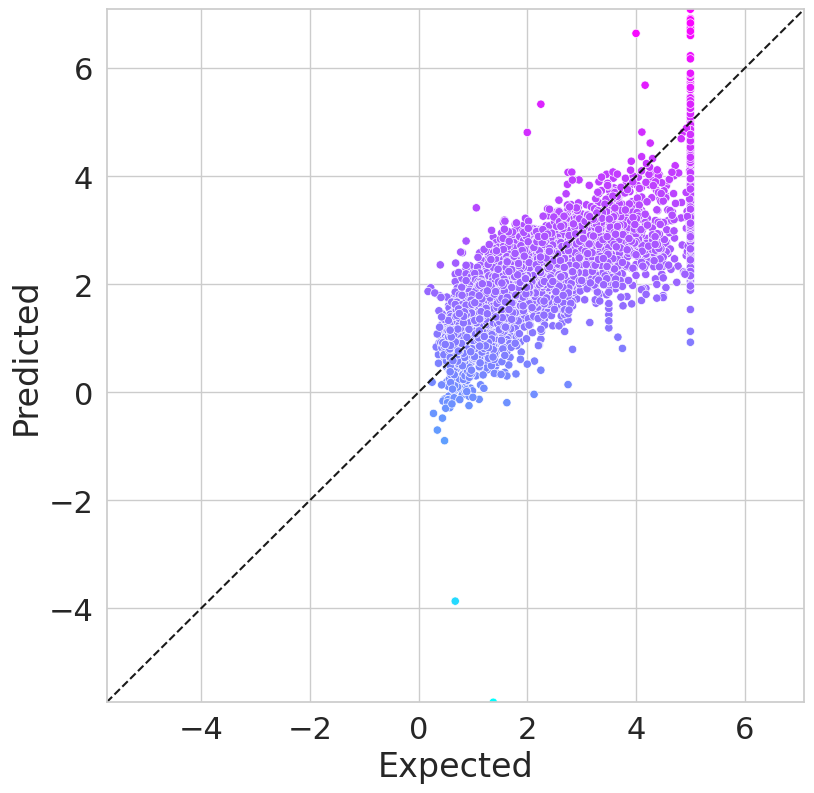

In [ ]:
#  Visualizando los precios esperado y los predichos
df = pd.DataFrame()
df['Expected'] = pd.Series(expected)
df['Predicted'] = pd.Series(predicted)

figure = plt.figure(figsize=(9, 9))
axes = sns.scatterplot(data=df, x='Expected', y='Predicted',
     hue='Predicted', palette='cool', legend=False)

start = min(expected.min(), predicted.min())
end = max(expected.max(), predicted.max())
axes.set_xlim(start, end)
axes.set_ylim(start, end)
line = plt.plot([start, end], [start, end], 'k--')

In [ ]:
# Metricas de la regresión
from sklearn import metrics

print(round(metrics.r2_score(expected, predicted), 3)) # bondad de ajuste
print(round(metrics.mean_squared_error(expected, predicted), 3))

0.596
0.542


In [ ]:
# Escogiendo el mejor modelo
from sklearn.linear_model import ElasticNet, Lasso, Ridge
estimators = {
    'LinearRegression': linear_regression,
    'ElasticNet': ElasticNet(),
    'Lasso': Lasso(),
    'Ridge': Ridge()
}

from sklearn.model_selection import KFold, cross_val_score

for estimator_name, estimator_object in estimators.items():
     kfold = KFold(n_splits=10, random_state=11, shuffle=True)
     scores = cross_val_score(estimator=estimator_object,
         X=california.data, y=california.target,
                              cv=kfold,
         scoring='r2')
     print(f'{estimator_name:>16}: ' +
           f'mean of r2 scores={scores.mean():.3f}')

LinearRegression: mean of r2 scores=0.599
      ElasticNet: mean of r2 scores=0.423
           Lasso: mean of r2 scores=0.285
           Ridge: mean of r2 scores=0.599
